In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

Device: cpu
Epoch  1/10 | Loss: 1.7964 | Learning rate: 0.10000
Epoch  2/10 | Loss: 1.6646 | Learning rate: 0.09000
Epoch  3/10 | Loss: 1.6034 | Learning rate: 0.08100
Epoch  4/10 | Loss: 1.5566 | Learning rate: 0.07290
Epoch  5/10 | Loss: 1.5167 | Learning rate: 0.06561
Epoch  6/10 | Loss: 1.4822 | Learning rate: 0.05905
Epoch  7/10 | Loss: 1.4537 | Learning rate: 0.05314
Epoch  8/10 | Loss: 1.4269 | Learning rate: 0.04783
Epoch  9/10 | Loss: 1.4035 | Learning rate: 0.04305
Epoch 10/10 | Loss: 1.3825 | Learning rate: 0.03874


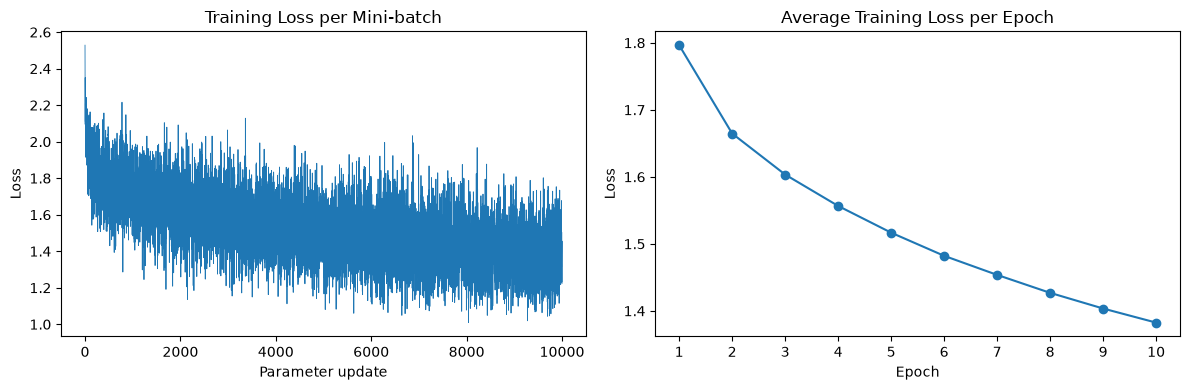


Training accuracy after 10 epochs: 53.77%
Test accuracy after 10 epochs: 48.03%


In [11]:
# Reproducibility
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 1. Data loading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

testset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# num_workers=0 works reliably in Windows notebooks.
trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

classes = (
    "plane", "car", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
)

# 2. Define network parameters
Din = 3 * 32 * 32
H = 100
K = 10

# Xavier initialization
w1 = torch.randn(Din, H, device=device) * (2.0 / (Din + H)) ** 0.5
b1 = torch.zeros(H, device=device)

w2 = torch.randn(H, K, device=device) * (2.0 / (H + K)) ** 0.5
b2 = torch.zeros(K, device=device)

# Hyperparameters
epochs = 10
lr = 0.1
lr_decay = 0.9
reg = 0.0

batch_loss_history = []
epoch_loss_history = []


# 3. Forward pass
def forward(x):
    hidden = torch.sigmoid(x.mm(w1) + b1)
    logits = hidden.mm(w2) + b2
    return hidden, logits


# 4. Training loop: all gradients are calculated manually
for epoch in range(epochs):
    running_loss = 0.0
    total_samples = 0

    for inputs, labels in trainloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        N = inputs.shape[0]
        x_train = inputs.reshape(N, -1)
        y_onehot = F.one_hot(labels, num_classes=K).float()

        # Forward pass
        hidden, logits = forward(x_train)

        # Stable log-softmax
        log_probs = logits - torch.logsumexp(
            logits, dim=1, keepdim=True
        )

        # Mean cross-entropy loss + L2 regularization
        data_loss = -(y_onehot * log_probs).sum(dim=1).mean()
        loss = data_loss + reg * (
            w1.square().sum() + w2.square().sum()
        )

        batch_loss_history.append(loss.item())
        running_loss += loss.item() * N
        total_samples += N

        # Backpropagation through softmax + cross-entropy
        probs = log_probs.exp()
        dlogits = (probs - y_onehot) / N

        # Output-layer gradients
        dw2 = hidden.t().mm(dlogits) + 2 * reg * w2
        db2 = dlogits.sum(dim=0)

        # Hidden-layer gradients
        dhidden = dlogits.mm(w2.t())
        dz_hidden = dhidden * hidden * (1 - hidden)

        dw1 = x_train.t().mm(dz_hidden) + 2 * reg * w1
        db1 = dz_hidden.sum(dim=0)

        # Update only after calculating all gradients
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    epoch_loss = running_loss / total_samples
    epoch_loss_history.append(epoch_loss)

    print(
        f"Epoch {epoch + 1:2d}/{epochs} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Learning rate: {lr:.5f}"
    )

    lr *= lr_decay


# 5. Plot training loss
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(batch_loss_history, linewidth=0.6)
axes[0].set_title("Training Loss per Mini-batch")
axes[0].set_xlabel("Parameter update")
axes[0].set_ylabel("Loss")

axes[1].plot(
    range(1, epochs + 1),
    epoch_loss_history,
    marker="o"
)
axes[1].set_title("Average Training Loss per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_xticks(range(1, epochs + 1))

plt.tight_layout()
plt.show()


# 6. Evaluate the final network
@torch.no_grad()
def calculate_accuracy(loader):
    correct = 0
    total = 0

    for inputs, labels in loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        x = inputs.reshape(inputs.shape[0], -1)
        _, logits = forward(x)

        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return 100.0 * correct / total


train_acc = calculate_accuracy(trainloader)
test_acc = calculate_accuracy(testloader)

print(f"\nTraining accuracy after {epochs} epochs: {train_acc:.2f}%")
print(f"Test accuracy after {epochs} epochs: {test_acc:.2f}%")

Q2

Device: cpu


100%|██████████| 9.91M/9.91M [00:14<00:00, 685kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 103kB/s]
100%|██████████| 1.65M/1.65M [00:02<00:00, 604kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.27MB/s]


Training images: 60000
Test images: 10000
LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=400, out_features=120, bias=True)
    (2): Tanh()
    (3): Linear(in_features=120, out_features=84, bias=True)
    (4): Tanh()
    (5): Linear(in_features=84, out_features=10, bias=True)
  )
)
Epoch  1/10 | Train loss: 0.0998 | Test loss: 0.0974 | Train accuracy: 96.98% | Test accuracy: 96.87%
Epoch  2/10 | Train loss: 0.0559 | Test loss: 0.0648 | Train accuracy: 98.23% | Test accuracy: 97.93%
Epoch  3/10 | Train loss: 0.0438 | Test loss: 0.0618 | Train accuracy: 98.62% | Test accuracy: 97.99%
Epoch  4/10 | Train loss: 0.0380 | Test loss: 0.0552 | Train accur

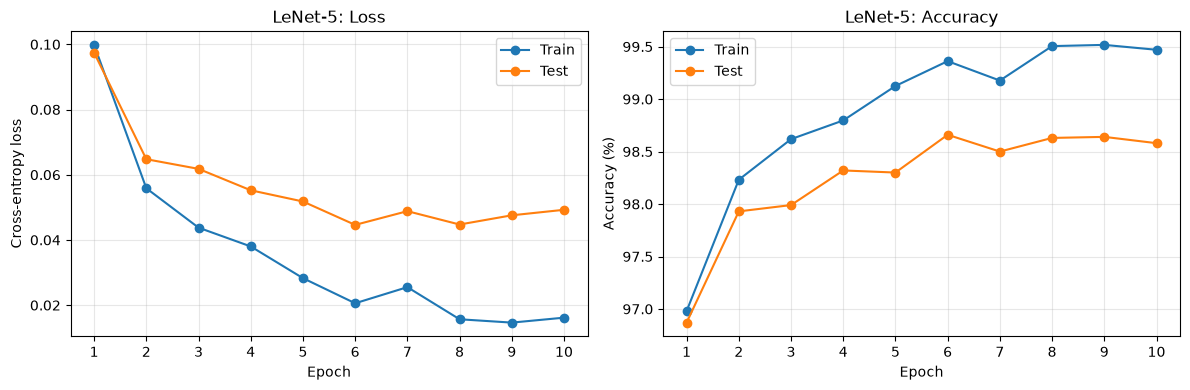

In [6]:
import random
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Reproducibility and device
SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 2. Load MNIST
# Pad 28 x 28 images to 32 x 32.
# Normalize pixel values from [0, 1] to [-1, 1].
transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

trainset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

testset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

batch_size = 64

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)

# Separate loader for evaluating the complete training set.
train_eval_loader = torch.utils.data.DataLoader(
    trainset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(trainset))
print("Test images:", len(testset))

# 3. Define LeNet-5
# Adaptation: fully connected convolutional channels and
# a linear classifier trained using cross-entropy.
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),     # 6 x 28 x 28
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2),       # 6 x 14 x 14

            nn.Conv2d(6, 16, kernel_size=5),    # 16 x 10 x 10
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2)        # 16 x 5 x 5
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120),
            nn.Tanh(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


lenet = LeNet5().to(device)
print(lenet)

# 4. Loss and optimizer
# CrossEntropyLoss takes raw logits: do not add softmax.
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(lenet.parameters(), lr=0.001)

epochs = 10

history_lenet = {
    "train_loss": [],
    "test_loss": [],
    "train_acc": [],
    "test_acc": []
}


# 5. Evaluation function
@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        loss = criterion(logits, labels)

        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, 100.0 * correct / total


# 6. Train for 10 epochs
for epoch in range(epochs):
    lenet.train()

    for images, labels in trainloader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = lenet(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

    # Evaluate both sets using the same end-of-epoch weights.
    train_loss, train_acc = evaluate(lenet, train_eval_loader)
    test_loss, test_acc = evaluate(lenet, testloader)

    history_lenet["train_loss"].append(train_loss)
    history_lenet["test_loss"].append(test_loss)
    history_lenet["train_acc"].append(train_acc)
    history_lenet["test_acc"].append(test_acc)

    print(
        f"Epoch {epoch + 1:2d}/{epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Test loss: {test_loss:.4f} | "
        f"Train accuracy: {train_acc:.2f}% | "
        f"Test accuracy: {test_acc:.2f}%"
    )

# 7. Final results: weights after exactly 10 epochs
print(f"\nTraining accuracy: {history_lenet['train_acc'][-1]:.2f}%")
print(f"Test accuracy: {history_lenet['test_acc'][-1]:.2f}%")

# 8. Plot per-epoch loss and accuracy
epoch_numbers = range(1, epochs + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    epoch_numbers, history_lenet["train_loss"], "o-", label="Train"
)
axes[0].plot(
    epoch_numbers, history_lenet["test_loss"], "o-", label="Test"
)
axes[0].set_title("LeNet-5: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(
    epoch_numbers, history_lenet["train_acc"], "o-", label="Train"
)
axes[1].plot(
    epoch_numbers, history_lenet["test_acc"], "o-", label="Test"
)
axes[1].set_title("LeNet-5: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()

for ax in axes:
    ax.set_xticks(list(epoch_numbers))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Q2(b)

SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.1, inplace=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout2d(p=0.2, inplace=False)
    (10): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Dropou

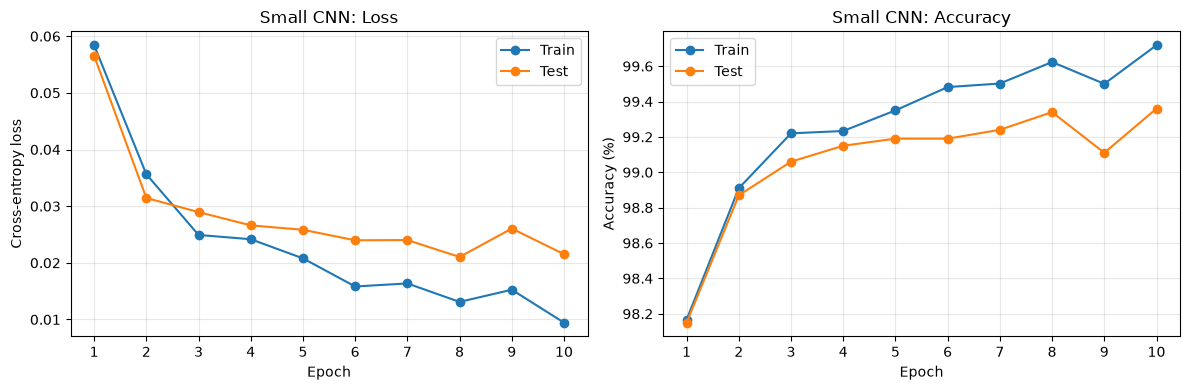


Results after 10 epochs
Model             Train accuracy    Test accuracy
LeNet-5                   99.47%           98.58%
Small CNN                 99.72%           99.36%


In [8]:
# 1. Reset seeds for reproducibility
random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Restart the training shuffle sequence for a fair comparison.
cnn_trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)


# 2. Define a CNN with three convolutional layers
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1: 1 x 32 x 32 -> 32 x 16 x 16
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.1),

            # Block 2: 32 x 16 x 16 -> 64 x 8 x 8
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.2),

            # Block 3: 64 x 8 x 8 -> 128 x 4 x 4
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.3)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


small_cnn = SmallCNN().to(device)
print(small_cnn)

# 3. Use the same optimizer settings as LeNet-5
cnn_optimizer = torch.optim.Adam(
    small_cnn.parameters(),
    lr=0.001
)

epochs = 10

history_cnn = {
    "train_loss": [],
    "test_loss": [],
    "train_acc": [],
    "test_acc": []
}

# 4. Train for 10 epochs
for epoch in range(epochs):
    # Enables dropout and batch-normalization updates.
    small_cnn.train()

    for images, labels in cnn_trainloader:
        images = images.to(device)
        labels = labels.to(device)

        cnn_optimizer.zero_grad()

        logits = small_cnn(images)
        loss = criterion(logits, labels)

        loss.backward()
        cnn_optimizer.step()

    # evaluate() switches to evaluation mode:
    # dropout is disabled and batch-normalization statistics are fixed.
    train_loss, train_acc = evaluate(small_cnn, train_eval_loader)
    test_loss, test_acc = evaluate(small_cnn, testloader)

    history_cnn["train_loss"].append(train_loss)
    history_cnn["test_loss"].append(test_loss)
    history_cnn["train_acc"].append(train_acc)
    history_cnn["test_acc"].append(test_acc)

    print(
        f"Epoch {epoch + 1:2d}/{epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Test loss: {test_loss:.4f} | "
        f"Train accuracy: {train_acc:.2f}% | "
        f"Test accuracy: {test_acc:.2f}%"
    )

# 5. Final results
print(f"\nTraining accuracy: {history_cnn['train_acc'][-1]:.2f}%")
print(f"Test accuracy: {history_cnn['test_acc'][-1]:.2f}%")

# 6. Plot per-epoch loss and accuracy
epoch_numbers = range(1, epochs + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    epoch_numbers, history_cnn["train_loss"], "o-", label="Train"
)
axes[0].plot(
    epoch_numbers, history_cnn["test_loss"], "o-", label="Test"
)
axes[0].set_title("Small CNN: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(
    epoch_numbers, history_cnn["train_acc"], "o-", label="Train"
)
axes[1].plot(
    epoch_numbers, history_cnn["test_acc"], "o-", label="Test"
)
axes[1].set_title("Small CNN: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()

for ax in axes:
    ax.set_xticks(list(epoch_numbers))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 7. Compare final results
print("\nResults after 10 epochs")
print(f"{'Model':<15} {'Train accuracy':>16} {'Test accuracy':>16}")
print(
    f"{'LeNet-5':<15} "
    f"{history_lenet['train_acc'][-1]:>15.2f}% "
    f"{history_lenet['test_acc'][-1]:>15.2f}%"
)
print(
    f"{'Small CNN':<15} "
    f"{history_cnn['train_acc'][-1]:>15.2f}% "
    f"{history_cnn['test_acc'][-1]:>15.2f}%"
)

Q2(c)

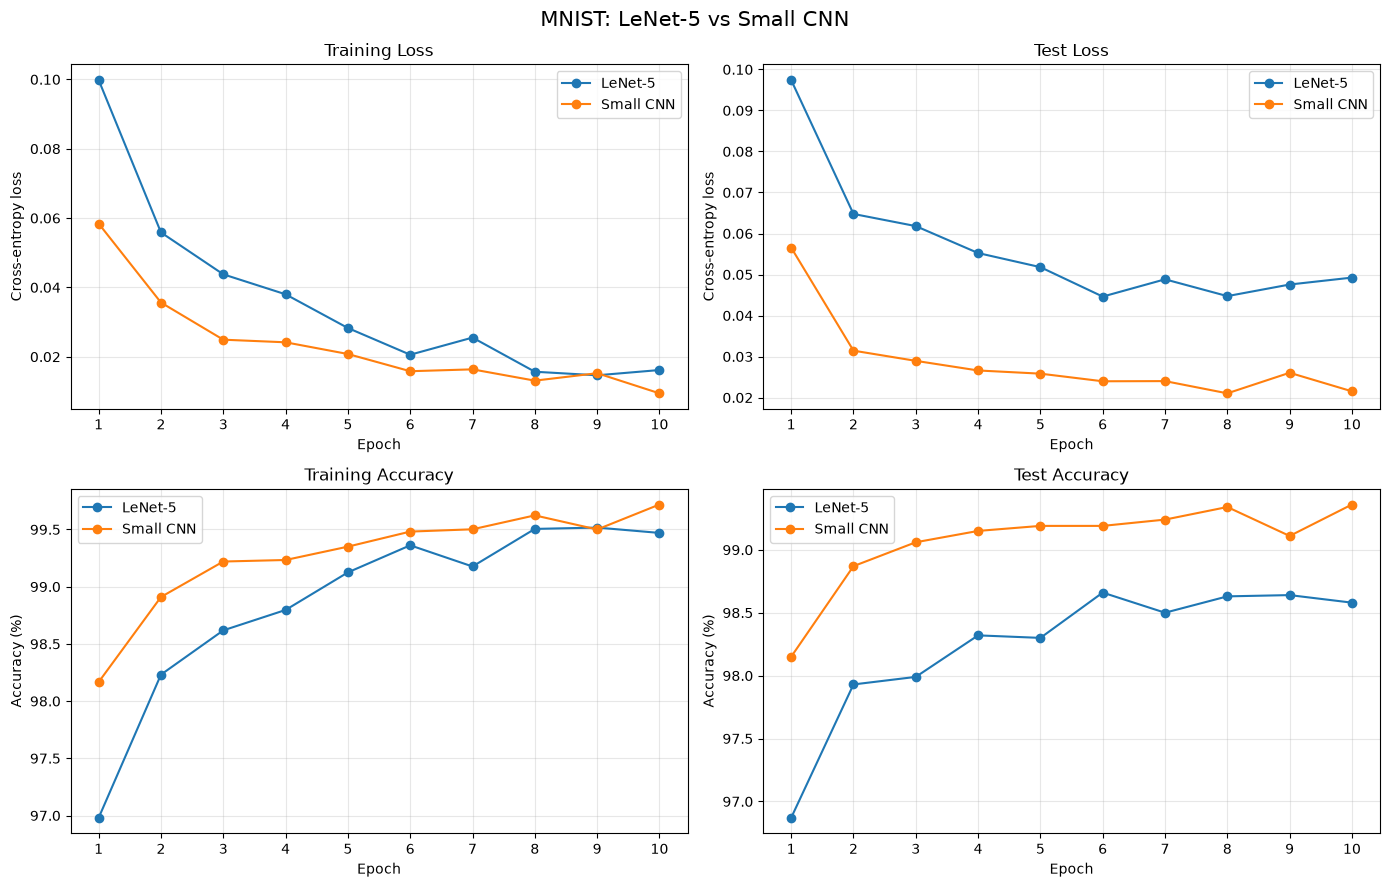

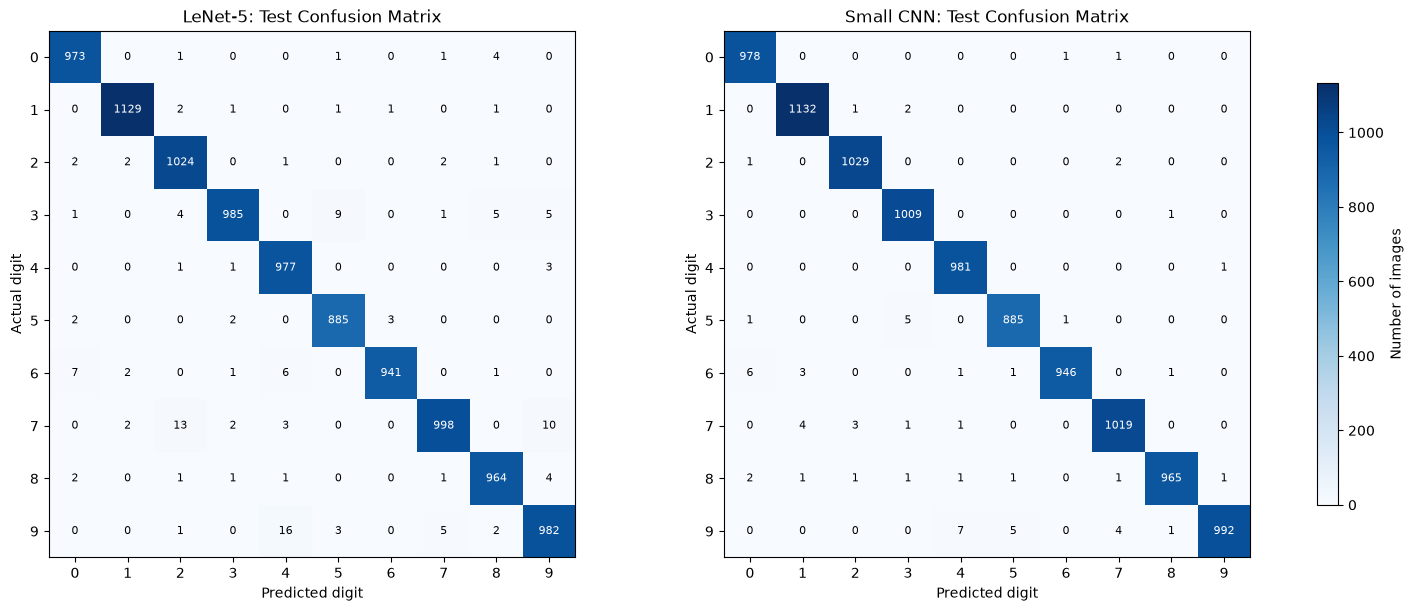

LeNet-5: test accuracy = 98.58%
Small CNN: test accuracy = 99.36%


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# 1. Compare per-epoch loss and accuracy
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

models_history = [
    ("LeNet-5", history_lenet),
    ("Small CNN", history_cnn)
]

for name, history in models_history:
    epochs_plot = range(1, len(history["train_loss"]) + 1)

    axes[0, 0].plot(
        epochs_plot, history["train_loss"], "o-", label=name
    )
    axes[0, 1].plot(
        epochs_plot, history["test_loss"], "o-", label=name
    )
    axes[1, 0].plot(
        epochs_plot, history["train_acc"], "o-", label=name
    )
    axes[1, 1].plot(
        epochs_plot, history["test_acc"], "o-", label=name
    )

titles = [
    "Training Loss", "Test Loss",
    "Training Accuracy", "Test Accuracy"
]

for ax, title in zip(axes.flat, titles):
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(
        "Accuracy (%)" if "Accuracy" in title
        else "Cross-entropy loss"
    )
    ax.xaxis.set_major_locator(
        plt.matplotlib.ticker.MaxNLocator(integer=True)
    )
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("MNIST: LeNet-5 vs Small CNN", fontsize=15)
plt.tight_layout()
plt.show()


# 2. Calculate test confusion matrices
@torch.no_grad()
def compute_confusion_matrix(model, loader, num_classes=10):
    model.eval()
    model_device = next(model.parameters()).device
    cm = torch.zeros(num_classes, num_classes, dtype=torch.int64)

    for images, labels in loader:
        images = images.to(model_device)
        predictions = model(images).argmax(dim=1).cpu()
        labels = labels.cpu()

        # Rows: actual classes; columns: predicted classes.
        indices = labels * num_classes + predictions
        cm += torch.bincount(
            indices, minlength=num_classes ** 2
        ).reshape(num_classes, num_classes)

    return cm.numpy()


cm_lenet = compute_confusion_matrix(lenet, testloader)
cm_cnn = compute_confusion_matrix(small_cnn, testloader)


# 3. Plot confusion matrices with a shared colour scale
fig, axes = plt.subplots(
    1, 2, figsize=(15, 6), constrained_layout=True
)

vmax = max(cm_lenet.max(), cm_cnn.max())

for ax, cm, name in zip(
    axes, [cm_lenet, cm_cnn], ["LeNet-5", "Small CNN"]
):
    image = ax.imshow(cm, cmap="Blues", vmin=0, vmax=vmax)

    ax.set_title(f"{name}: Test Confusion Matrix")
    ax.set_xlabel("Predicted digit")
    ax.set_ylabel("Actual digit")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))

    for actual in range(10):
        for predicted in range(10):
            count = cm[actual, predicted]
            ax.text(
                predicted, actual, str(count),
                ha="center", va="center",
                color="white" if count > vmax / 2 else "black",
                fontsize=8
            )

fig.colorbar(image, ax=axes, label="Number of images", shrink=0.8)
plt.show()


# 4. Verify confusion-matrix totals and print test accuracy
for name, cm in [("LeNet-5", cm_lenet), ("Small CNN", cm_cnn)]:
    assert cm.sum() == len(testloader.dataset)
    accuracy = 100 * np.trace(cm) / cm.sum()
    print(f"{name}: test accuracy = {accuracy:.2f}%")